# 02 — Customer / HCP Segmentation
RFM-style scoring and segmentation of healthcare providers, matching
**Module 2: Customer / HCP Analytics**.

This notebook re-derives (and visualizes) what
`src/feature_engineering.py` computes and writes to
`data/processed/hcp_features.csv`.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED_DIR = os.path.join("..", "data", "processed")

hcp_features = pd.read_csv(os.path.join(PROCESSED_DIR, "hcp_features.csv"))
hcp_features.head()

,hcp_id,specialty,primary_therapy_area,city,state,hospital_type,hcp_segment,monetary_value,frequency,last_engagement_date,last_sales_date,last_activity_date,recency_days,sales_last_6m,sales_prior_6m,growth_pct,monetary_score,recency_score,frequency_score,value_growth_segment
0,H0001,Oncologist,Oncology,Mysuru,Karnataka,Private,Low potential,448828.32,93,2024-12-09,2024-12-01,2024-12-09,-8,89963.68,65856.85,36.604894,2,2,1,Low Activity
1,H0002,General Physician,Respiratory,Ahmedabad,Gujarat,Corporate Chain,Low potential,359472.84,103,2024-12-15,2024-12-01,2024-12-15,-14,64104.18,46264.26,38.560911,2,2,2,Low Activity
2,H0003,General Physician,Cardiology,Thiruvananthapuram,Kerala,Trust/NGO,High potential,2397651.46,708,2024-12-26,2024-12-01,2024-12-26,-25,446168.70,511367.44,-12.749881,4,4,4,Emerging HCP
3,H0004,General Physician,Cardiology,Faridabad,Haryana,Trust/NGO,Medium potential,962392.39,269,2024-12-20,2024-12-01,2024-12-20,-19,168737.78,122091.20,38.206341,2,3,2,Emerging HCP
4,H0005,Oncologist,Oncology,Ahmedabad,Gujarat,Private,Medium potential,1175305.26,303,2024-12-13,2024-12-01,2024-12-13,-12,196278.57,221820.83,-11.514816,3,2,3,High Value / Low Engagement


## Segment distribution

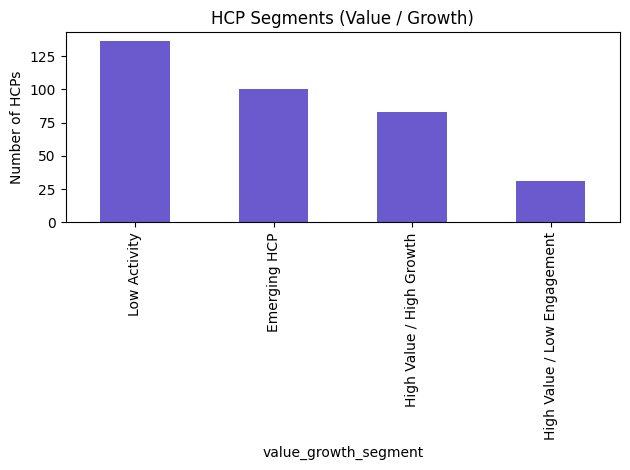

value_growth_segment
Low Activity                   136
Emerging HCP                   100
High Value / High Growth        83
High Value / Low Engagement     31
Name: count, dtype: int64

In [2]:
segment_counts = hcp_features["value_growth_segment"].value_counts()
segment_counts.plot(kind="bar", title="HCP Segments (Value / Growth)", color="slateblue")
plt.ylabel("Number of HCPs")
plt.tight_layout()
plt.show()
segment_counts

## Monetary value distribution by segment

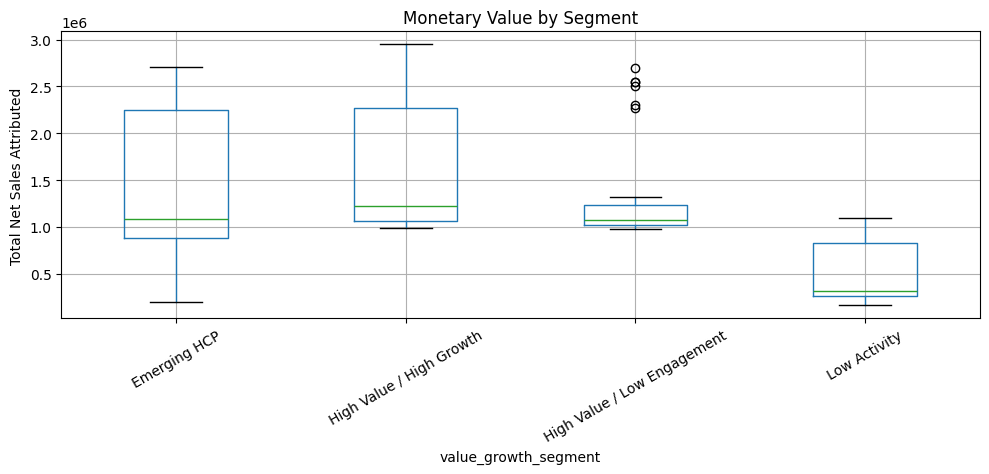

In [3]:
hcp_features.boxplot(column="monetary_value", by="value_growth_segment", rot=30, figsize=(10, 5))
plt.title("Monetary Value by Segment")
plt.suptitle("")
plt.ylabel("Total Net Sales Attributed")
plt.tight_layout()
plt.show()

## Top 15 highest-value HCPs

In [4]:
hcp_features.sort_values("monetary_value", ascending=False).head(15)[
    ["hcp_id", "specialty", "state", "hcp_segment", "monetary_value", "frequency", "recency_days", "growth_pct", "value_growth_segment"]
]

,hcp_id,specialty,state,hcp_segment,monetary_value,frequency,recency_days,growth_pct,value_growth_segment
246,H0247,Oncologist,Maharashtra,High potential,2949322.51,789,-18,16.801991,High Value / High Growth
269,H0270,Hematologist,Karnataka,High potential,2874240.24,722,0,26.161470,High Value / High Growth
157,H0158,Oncologist,Bihar,High potential,2804178.85,762,-26,39.968971,High Value / High Growth
21,H0022,Hematologist,Maharashtra,High potential,2759636.41,735,-25,10.568539,High Value / High Growth
300,H0301,Oncologist,Madhya Pradesh,High potential,2708160.05,696,-26,4.939323,Emerging HCP
270,H0271,Oncologist,West Bengal,High potential,2700394.59,708,-23,-22.825131,Emerging HCP
125,H0126,General Physician,Karnataka,High potential,2698744.08,738,-9,4.039574,High Value / Low Engagement
91,H0092,Cardiologist,Tamil Nadu,High potential,2698014.22,852,-21,0.307148,Emerging HCP
104,H0105,Oncologist,Chhattisgarh,High potential,2693557.87,727,-18,-12.217619,Emerging HCP
121,H0122,Cardiologist,Madhya Pradesh,High potential,2664586.72,771,-20,9.387297,Emerging HCP


## High-potential HCPs with low engagement (targeting opportunity)
These are HCPs the company has classified as *High potential* but who
score low on recency/engagement — a natural target list for field
teams.

In [5]:
targets = hcp_features[
    (hcp_features["hcp_segment"] == "High potential")
    & (hcp_features["value_growth_segment"] == "High Value / Low Engagement")
].sort_values("monetary_value", ascending=False)
targets

,hcp_id,specialty,primary_therapy_area,city,state,hospital_type,hcp_segment,monetary_value,frequency,last_engagement_date,last_sales_date,last_activity_date,recency_days,sales_last_6m,sales_prior_6m,growth_pct,monetary_score,recency_score,frequency_score,value_growth_segment
125,H0126,General Physician,Cardiology,Mysuru,Karnataka,Government,High potential,2698744.08,738,2024-12-10,2024-12-01,2024-12-10,-9,550949.14,529557.28,4.039574,4,2,4,High Value / Low Engagement
120,H0121,Oncologist,Oncology,Faridabad,Haryana,Trust/NGO,High potential,2546596.82,659,2024-12-07,2024-12-01,2024-12-07,-6,448077.51,450543.28,-0.547288,4,2,4,High Value / Low Engagement
181,H0182,Cardiologist,Cardiology,Jaipur,Rajasthan,Corporate Chain,High potential,2543837.58,761,2024-12-12,2024-12-01,2024-12-12,-11,531590.56,501482.84,6.003739,4,2,4,High Value / Low Engagement
288,H0289,General Physician,Diabetes,Mysuru,Karnataka,Government,High potential,2501184.95,669,2024-12-16,2024-12-01,2024-12-16,-15,345717.41,550137.93,-37.158049,4,2,4,High Value / Low Engagement
173,H0174,General Physician,Diabetes,Ludhiana,Punjab,Government,High potential,2301959.67,685,2024-12-16,2024-12-01,2024-12-16,-15,461050.19,428102.89,7.696117,4,2,4,High Value / Low Engagement
124,H0125,Pulmonologist,Respiratory,Surat,Gujarat,Private,High potential,2273399.77,722,2024-12-13,2024-12-01,2024-12-13,-12,416254.22,463562.34,-10.205342,4,2,4,High Value / Low Engagement


## Recency vs Monetary scatter (quick visual RFM check)

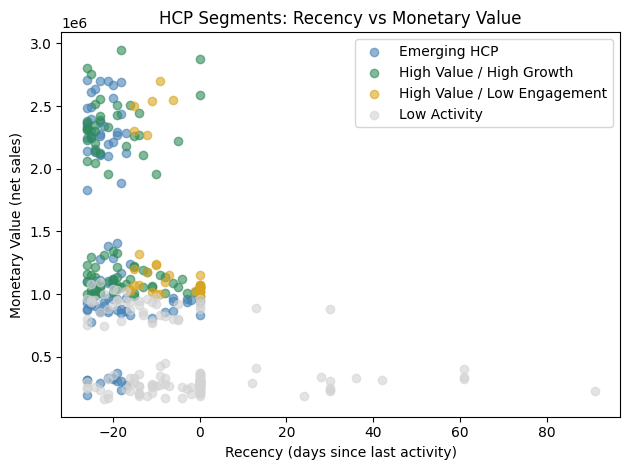

In [6]:
colors = {
    "High Value / High Growth": "seagreen",
    "High Value / Low Engagement": "goldenrod",
    "Emerging HCP": "steelblue",
    "Low Activity": "lightgray",
}
fig, ax = plt.subplots()
for seg, grp in hcp_features.groupby("value_growth_segment"):
    ax.scatter(grp["recency_days"], grp["monetary_value"], label=seg, alpha=0.6, color=colors.get(seg))
ax.set_xlabel("Recency (days since last activity)")
ax.set_ylabel("Monetary Value (net sales)")
ax.legend()
plt.title("HCP Segments: Recency vs Monetary Value")
plt.tight_layout()
plt.show()